## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/Frogs_MFCCs.csv")
X = df.iloc[:, 0:22]
y = df[["Family", "Genus", "Species"]]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.70, random_state=42, shuffle=True
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (5036, 22), X_test shape: (2159, 22)


### 1(b)(i) Evaluation Metrics: Exact Match and Hamming Score/Loss

Each instance has $L = 3$ labels (Family, Genus, Species). For $n$ test instances with true labels $y_{ij}$ and predicted labels $\hat{y}_{ij}$:

- **Exact match ratio:** fraction of instances where all three predicted labels are correct. It is strict, since one wrong label makes the whole instance wrong.

$$\text{Exact Match} = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\hat{y}_{i1}=y_{i1},\ \hat{y}_{i2}=y_{i2},\ \hat{y}_{i3}=y_{i3}\right]$$

- **Hamming loss:** fraction of individual label predictions that are wrong, over all instances and all labels.

$$\text{Hamming Loss} = \frac{1}{nL}\sum_{i=1}^{n}\sum_{j=1}^{L} \mathbb{1}\left[\hat{y}_{ij} \neq y_{ij}\right]$$

- **Hamming score:** fraction of individual label predictions that are correct.

$$\text{Hamming Score} = 1 - \text{Hamming Loss}$$

The cell below implements these metrics and demonstrates them on an untuned baseline: one Gaussian-kernel SVM per label (binary relevance), with one-vs-all classification within each label. Tuned models follow in 1(b)(ii).

In [11]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier

labels = ["Family", "Genus", "Species"]


def evaluate_multilabel(y_true, y_pred):
    """Return exact match ratio, Hamming loss, and Hamming score."""
    y_true_arr = np.asarray(y_true)
    y_pred_arr = np.asarray(y_pred)

    # Exact match: all 3 labels must be correct for the row
    exact_match = np.mean(np.all(y_true_arr == y_pred_arr, axis=1))

    # Hamming loss: fraction of individual labels that are wrong
    hamming_loss = np.mean(y_true_arr != y_pred_arr)

    # Hamming score: fraction of individual labels that are correct
    hamming_score = 1.0 - hamming_loss

    return exact_match, hamming_loss, hamming_score


# Untuned baseline to demonstrate the metrics:
# one RBF SVM per label (binary relevance), one-vs-all within each label
models = {}
y_pred_dict = {}

for label in labels:
    clf = OneVsRestClassifier(SVC(kernel="rbf"))
    clf.fit(X_train, y_train[label])

    models[label] = clf
    y_pred_dict[label] = clf.predict(X_test)

y_pred_df = pd.DataFrame(y_pred_dict, index=y_test.index)

# Evaluate on the test set (select columns by name so order always matches)
exact_match, h_loss, h_score = evaluate_multilabel(y_test[labels], y_pred_df[labels])

print(f"Exact Match Ratio: {exact_match:.4f}")
print(f"Hamming Loss:      {h_loss:.4f}")
print(f"Hamming Score:     {h_score:.4f}")
wrong_per_row = (np.asarray(y_test[labels]) != np.asarray(y_pred_df[labels])).sum(axis=1)
print(f"Rows with at least one error: {(wrong_per_row > 0).sum()}")
print(f"Avg wrong labels per erroneous row: {wrong_per_row[wrong_per_row > 0].mean():.2f}")

Exact Match Ratio: 0.9555
Hamming Loss:      0.0307
Hamming Score:     0.9693
Rows with at least one error: 96
Avg wrong labels per erroneous row: 2.07


**Baseline results (untuned, test set):**

| Metric | Value |
|---|---|
| Exact Match Ratio | 0.9555 |
| Hamming Loss | 0.0307 |
| Hamming Score | 0.9693 |

Even without tuning, the Gaussian-kernel SVMs predict all three labels correctly for 95.55% of test instances, and only 3.07% of individual label predictions are wrong. Exact match is lower than the Hamming score because it requires all three labels to be correct at once.

About 96 of the 2159 test instances have at least one wrong label, with roughly 2 wrong labels each on average. So errors tend to occur together across labels, which is expected since Family, Genus, and Species are hierarchically related: a call that is misclassified at one level is often misclassified at another.

### 1(b)(ii) SVM with Gaussian Kernel, One-vs-All

A Gaussian (RBF) kernel SVM is trained for each of the three labels, using a one-versus-all scheme within each label. The penalty weight $C$ and the kernel width $\sigma$ are chosen jointly by 10-fold stratified cross validation on the training set. Since scikit-learn parameterizes the kernel with $\gamma$, each $\sigma$ is converted using $\gamma = \frac{1}{2\sigma^2}$.

**Parameter grid.** To keep computation feasible, a coarser grid was used:
- $C \in \{10^{-1}, 10^{0}, \dots, 10^{4}\}$ (log scale)
- Raw attributes: 7 linearly spaced values, $\sigma \in \{0.2, 0.5, \dots, 2.0\}$
- Standardized attributes: 7 linearly spaced values, $\sigma \in \{1.0, 2.5, \dots, 10.0\}$

Standardizing increases the distances between points, so the standardized run uses larger kernel widths.

The problem is solved with both raw and standardized attributes. For the standardized run, the scaler is placed inside a pipeline so it is refit on the training portion of every CV fold, which prevents information from the validation fold leaking into the scaling.

In [13]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

labels = ["Family", "Genus", "Species"]

# Penalty weight C: 10^-1 to 10^4 on a log scale
C_range = np.logspace(-1, 4, 6)

# Kernel width sigma in linear increments; sklearn uses gamma = 1 / (2 * sigma^2).
# Standardizing increases distances between points, so that run needs larger sigmas.
sigma_raw = np.linspace(0.2, 2.0, 7)    # 0.2, 0.5, ..., 2.0
sigma_std = np.linspace(1.0, 10.0, 7)   # 1.0, 2.5, ..., 10.0


def run_ovr_gaussian_svm(X_tr, X_te, y_tr, y_te, sigma_range, standardize, dataset_name):
    """Tune and evaluate one one-vs-all Gaussian SVM per label with 10-fold CV."""
    gamma_range = 1.0 / (2.0 * sigma_range**2)
    param_grid = {"clf__estimator__C": C_range, "clf__estimator__gamma": gamma_range}

    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    y_pred_dict = {}
    summary = []

    for label in labels:
        # Scaler sits inside the pipeline so it is refit on each CV training fold
        steps = [("scaler", StandardScaler())] if standardize else []
        steps.append(("clf", OneVsRestClassifier(SVC(kernel="rbf", cache_size=1000))))

        grid = GridSearchCV(
        estimator=Pipeline(steps),
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
        verbose=1,
    )
        grid.fit(X_tr, y_tr[label])

        best_C = grid.best_params_["clf__estimator__C"]
        best_gamma = grid.best_params_["clf__estimator__gamma"]
        best_sigma = np.sqrt(1.0 / (2.0 * best_gamma))

        y_pred_dict[label] = grid.predict(X_te)
        test_acc = np.mean(y_pred_dict[label] == y_te[label].to_numpy())

        summary.append({
            "Dataset": dataset_name,
            "Label": label,
            "Best C": best_C,
            "Best Sigma": round(best_sigma, 2),
            "Best Gamma": round(best_gamma, 4),
            "10-Fold CV Accuracy": round(grid.best_score_, 4),
            "Test Accuracy": round(test_acc, 4),
        })

    y_pred_df = pd.DataFrame(y_pred_dict, index=y_te.index)
    exact_match, h_loss, h_score = evaluate_multilabel(y_te[labels], y_pred_df[labels])

    metrics = {
        "Dataset": dataset_name,
        "Exact Match Ratio": round(exact_match, 4),
        "Hamming Loss": round(h_loss, 4),
        "Hamming Score": round(h_score, 4),
    }
    return pd.DataFrame(summary), metrics, y_pred_df


# Raw attributes
raw_params_df, raw_metrics, raw_pred_df = run_ovr_gaussian_svm(
    X_train, X_test, y_train, y_test, sigma_raw, standardize=False, dataset_name="Raw"
)

# Standardized attributes
std_params_df, std_metrics, std_pred_df = run_ovr_gaussian_svm(
    X_train, X_test, y_train, y_test, sigma_std, standardize=True, dataset_name="Standardized"
)

print("Best hyperparameters per label")
display(pd.concat([raw_params_df, std_params_df], ignore_index=True))

print("Test set multi-label evaluation")
display(pd.DataFrame([raw_metrics, std_metrics]))

Fitting 10 folds for each of 42 candidates, totalling 420 fits
Fitting 10 folds for each of 42 candidates, totalling 420 fits
Fitting 10 folds for each of 42 candidates, totalling 420 fits
Fitting 10 folds for each of 42 candidates, totalling 420 fits
Fitting 10 folds for each of 42 candidates, totalling 420 fits
Fitting 10 folds for each of 42 candidates, totalling 420 fits
Best hyperparameters per label


,Dataset,Label,Best C,Best Sigma,Best Gamma,10-Fold CV Accuracy,Test Accuracy
0,Raw,Family,100.0,0.5,2.0000,0.9927,0.9954
1,Raw,Genus,10.0,0.5,2.0000,0.9915,0.9907
2,Raw,Species,100.0,0.5,2.0000,0.9911,0.9912
3,Standardized,Family,1000.0,4.0,0.0312,0.9921,0.9944
4,Standardized,Genus,10.0,4.0,0.0312,0.9905,0.9884
5,Standardized,Species,100.0,4.0,0.0312,0.9903,0.9893


Test set multi-label evaluation


,Dataset,Exact Match Ratio,Hamming Loss,Hamming Score
0,Raw,0.9889,0.0076,0.9924
1,Standardized,0.9866,0.0093,0.9907


#### Results

**Best hyperparameters and accuracy per label**

| Dataset | Label | Best C | Best σ | Best γ | 10-Fold CV Accuracy | Test Accuracy |
|---|---|---|---|---|---|---|
| Raw | Family | 100 | 0.5 | 2.0000 | 0.9927 | 0.9954 |
| Raw | Genus | 10 | 0.5 | 2.0000 | 0.9915 | 0.9907 |
| Raw | Species | 100 | 0.5 | 2.0000 | 0.9911 | 0.9912 |
| Standardized | Family | 1000 | 4.0 | 0.0312 | 0.9921 | 0.9944 |
| Standardized | Genus | 10 | 4.0 | 0.0312 | 0.9905 | 0.9884 |
| Standardized | Species | 100 | 4.0 | 0.0312 | 0.9903 | 0.9893 |

**Multi-label evaluation on the test set**

| Dataset | Exact Match Ratio | Hamming Loss | Hamming Score |
|---|---|---|---|
| Raw | 0.9889 | 0.0076 | 0.9924 |
| Standardized | 0.9866 | 0.0093 | 0.9907 |

**Observations**

- Tuning matters. Compared with the untuned baseline in 1(b)(i), exact match rises from 0.9555 to 0.9889 and Hamming loss drops from 0.0307 to 0.0076 on raw attributes.
- All selected values of $C$ and $\sigma$ lie in the interior of their grids, so the search ranges bracket the optimum.
- Each label reaches about 99% test accuracy, and test accuracy is close to the 10-fold CV accuracy in every case, so there is no sign of overfitting.
- Raw and standardized attributes perform almost identically. Raw is marginally better (exact match 0.9889 vs 0.9866), a difference of only about 5 test instances out of 2159. This is consistent with the data already being normalized, so standardizing adds no benefit here.
- The selected $\sigma$ is the same across all three labels within each data set (0.5 raw, 4.0 standardized), and it is larger for standardized data, as expected from the larger feature scale.

### 1(b)(iii) L1-Penalized SVM

A linear-kernel SVM with an L1 penalty is trained for each of the three labels, using one-versus-all classification within each label. Following the convention noted in the assignment, the L1 penalty is used with a linear kernel. The L1 penalty shrinks coefficients toward zero and can set some exactly to zero, which performs feature selection.

The attributes are standardized. The scaler is placed inside a pipeline so it is refit on the training portion of every CV fold. The penalty weight is chosen by 10-fold stratified cross validation over $C \in \{10^{-3}, 10^{-2}, \dots, 10^{6}\}$ (log scale).

In [15]:
import warnings
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

# Suppress convergence warnings at extreme C values during grid search
warnings.filterwarnings("ignore", category=ConvergenceWarning)

labels = ["Family", "Genus", "Species"]

# Penalty weight C: 10^-3 to 10^6 on a log scale
param_grid = {"clf__C": np.logspace(-3, 6, 10)}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
l1_pred_dict = {}
l1_summary = []

for label in labels:
    # Scaler sits inside the pipeline so it is refit on each CV training fold.
    # LinearSVC is one-vs-rest by default; penalty="l1" requires dual=False.
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LinearSVC(penalty="l1", dual=False, max_iter=10000, random_state=42)),
    ])

    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
        verbose=1,
    )
    grid.fit(X_train, y_train[label])

    l1_pred_dict[label] = grid.predict(X_test)
    test_acc = np.mean(l1_pred_dict[label] == y_test[label].to_numpy())

    # Features whose coefficient is zero in every one-vs-rest classifier
    coef = grid.best_estimator_.named_steps["clf"].coef_
    n_zero_features = int(np.sum(np.all(coef == 0, axis=0)))

    l1_summary.append({
        "Label": label,
        "Best C": grid.best_params_["clf__C"],
        "10-Fold CV Accuracy": round(grid.best_score_, 4),
        "Test Accuracy": round(test_acc, 4),
        "Features Dropped (of 22)": n_zero_features,
    })

l1_pred_df = pd.DataFrame(l1_pred_dict, index=y_test.index)
exact_match, h_loss, h_score = evaluate_multilabel(y_test[labels], l1_pred_df[labels])

l1_metrics = {
    "Dataset": "L1 Linear SVM (Standardized)",
    "Exact Match Ratio": round(exact_match, 4),
    "Hamming Loss": round(h_loss, 4),
    "Hamming Score": round(h_score, 4),
}

print("Best penalty weight per label")
display(pd.DataFrame(l1_summary))

print("Test set multi-label evaluation")
display(pd.DataFrame([l1_metrics]))

Fitting 10 folds for each of 10 candidates, totalling 100 fits
Fitting 10 folds for each of 10 candidates, totalling 100 fits
Fitting 10 folds for each of 10 candidates, totalling 100 fits
Best penalty weight per label


,Label,Best C,10-Fold CV Accuracy,Test Accuracy,Features Dropped (of 22)
0,Family,10.0,0.9412,0.9282,0
1,Genus,1000.0,0.9517,0.9416,0
2,Species,10.0,0.9607,0.9592,0


Test set multi-label evaluation


,Dataset,Exact Match Ratio,Hamming Loss,Hamming Score
0,L1 Linear SVM (Standardized),0.9125,0.057,0.943


#### Results

**Best penalty weight and accuracy per label**

| Label | Best C | 10-Fold CV Accuracy | Test Accuracy | Features Dropped (of 22) |
|---|---|---|---|---|
| Family | 10 | 0.9412 | 0.9282 | 0 |
| Genus | 1000 | 0.9517 | 0.9416 | 0 |
| Species | 10 | 0.9607 | 0.9592 | 0 |

**Multi-label evaluation on the test set**

| Model | Exact Match Ratio | Hamming Loss | Hamming Score |
|---|---|---|---|
| L1 Linear SVM (Standardized) | 0.9125 | 0.0570 | 0.9430 |

**Observations**

- The L1-penalized linear SVM performs clearly worse than the Gaussian-kernel SVM from 1(b)(ii). Exact match falls from 0.9889 to 0.9125, and Hamming loss rises from 0.0076 to 0.0570, roughly 7.5 times higher. This indicates the classes are not linearly separable in the MFCC feature space, so the nonlinear Gaussian kernel fits the data better.
- All selected values of $C$ lie in the interior of the grid, so the search range brackets the optimum.
- No features are dropped at the selected values of $C$. Cross validation prefers a fairly large $C$ (a weak penalty), so the L1 penalty does not zero out any feature across all one-vs-all classifiers. This suggests all 22 MFCC features carry useful information for classification.
- Accuracy increases from Family to Genus to Species, the opposite of what the number of classes would suggest. A likely reason is that a family groups several distinct species together, so separating one family from the rest with a single linear boundary is harder than separating one compact species from the rest.
- Test accuracy is close to the CV accuracy for each label (largest gap is about 1.3% for Family), so the models generalize reasonably well.

### 1(b)(iv) L1-Penalized SVM with SMOTE

The classes within each label are heavily imbalanced in the training set:

| Label | Largest Class | Smallest Class | Ratio |
|---|---|---|---|
| Family | Leptodactylidae (3073) | Bufonidae (41) | about 75 : 1 |
| Genus | Adenomera (2899) | Rhinella (41) | about 71 : 1 |
| Species | AdenomeraHylaedactylus (2447) | Rhinellagranulosa (41) | about 60 : 1 |

To remedy this, SMOTE (Synthetic Minority Over-sampling Technique) is applied. SMOTE creates synthetic minority-class points by interpolating between a minority point and its nearest minority-class neighbors, until every class has as many training points as the largest class.

The L1-penalized linear SVM from 1(b)(iii) is then retrained. The pipeline is: standardize, then SMOTE, then the SVM. SMOTE is applied inside the pipeline, so in each of the 10 cross-validation folds only the training portion is oversampled. The validation folds and the test set contain only real observations, which prevents synthetic points from leaking into the evaluation. The penalty weight is chosen by 10-fold stratified cross validation over $C \in \{10^{-3}, 10^{-2}, \dots, 10^{6}\}$ (log scale).

Because overall accuracy is dominated by the large classes, macro-averaged F1 is also reported. It weights every class equally, so it shows the effect of SMOTE on the minority classes.

In [16]:
# %pip install imbalanced-learn  # Uncomment and run once if imblearn is not installed

import warnings
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

labels = ["Family", "Genus", "Species"]

# Class counts in the training set, to show the imbalance
for label in labels:
    print(f"{label} class counts (training set):")
    print(y_train[label].value_counts().to_string(), "\n")

# Penalty weight C: 10^-3 to 10^6 on a log scale
param_grid = {"clf__C": np.logspace(-3, 6, 10)}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
smote_pred_dict = {}
smote_summary = []

for label in labels:
    # Scale -> SMOTE -> L1 linear SVM. imblearn's pipeline applies SMOTE only when
    # fitting, so each CV validation fold and the test set are never oversampled.
    pipe = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("clf", LinearSVC(penalty="l1", dual=False, max_iter=10000, random_state=42)),
    ])

    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
        verbose=1,
    )
    grid.fit(X_train, y_train[label])

    smote_pred_dict[label] = grid.predict(X_test)
    y_true = y_test[label].to_numpy()

    smote_summary.append({
        "Label": label,
        "Best C": grid.best_params_["clf__C"],
        "10-Fold CV Accuracy": round(grid.best_score_, 4),
        "Test Accuracy (SMOTE)": round(np.mean(smote_pred_dict[label] == y_true), 4),
        "Test Accuracy (no SMOTE)": round(np.mean(l1_pred_df[label].to_numpy() == y_true), 4),
        "Macro F1 (SMOTE)": round(f1_score(y_true, smote_pred_dict[label], average="macro"), 4),
        "Macro F1 (no SMOTE)": round(f1_score(y_true, l1_pred_df[label], average="macro"), 4),
    })

smote_pred_df = pd.DataFrame(smote_pred_dict, index=y_test.index)
exact_match, h_loss, h_score = evaluate_multilabel(y_test[labels], smote_pred_df[labels])

smote_metrics = {
    "Dataset": "SMOTE + L1 Linear SVM (Standardized)",
    "Exact Match Ratio": round(exact_match, 4),
    "Hamming Loss": round(h_loss, 4),
    "Hamming Score": round(h_score, 4),
}

print("Best penalty weight per label, with and without SMOTE")
display(pd.DataFrame(smote_summary))

print("Test set multi-label evaluation: all models")
display(pd.DataFrame([raw_metrics, std_metrics, l1_metrics, smote_metrics]))

Family class counts (training set):
Family
Leptodactylidae    3073
Hylidae            1542
Dendrobatidae       380
Bufonidae            41 

Genus class counts (training set):
Genus
Adenomera        2899
Hypsiboas        1125
Ameerega          380
Dendropsophus     226
Leptodactylus     174
Scinax            111
Osteocephalus      80
Rhinella           41 

Species class counts (training set):
Species
AdenomeraHylaedactylus    2447
HypsiboasCordobae          788
AdenomeraAndre             452
Ameeregatrivittata         380
HypsiboasCinerascens       337
HylaMinuta                 226
LeptodactylusFuscus        174
ScinaxRuber                111
OsteocephalusOophagus       80
Rhinellagranulosa           41 

Fitting 10 folds for each of 10 candidates, totalling 100 fits
Fitting 10 folds for each of 10 candidates, totalling 100 fits
Fitting 10 folds for each of 10 candidates, totalling 100 fits
Best penalty weight per label, with and without SMOTE


,Label,Best C,10-Fold CV Accuracy,Test Accuracy (SMOTE),Test Accuracy (no SMOTE),Macro F1 (SMOTE),Macro F1 (no SMOTE)
0,Family,10.0,0.9232,0.9092,0.9282,0.7947,0.6828
1,Genus,1.0,0.9128,0.9023,0.9416,0.8024,0.8091
2,Species,10.0,0.9581,0.9579,0.9592,0.9042,0.9060


Test set multi-label evaluation: all models


,Dataset,Exact Match Ratio,Hamming Loss,Hamming Score
0,Raw,0.9889,0.0076,0.9924
1,Standardized,0.9866,0.0093,0.9907
2,L1 Linear SVM (Standardized),0.9125,0.0570,0.9430
3,SMOTE + L1 Linear SVM (Standardized),0.8536,0.0769,0.9231


#### Results

**L1-penalized linear SVM with and without SMOTE (test set)**

| Label | Best C | 10-Fold CV Accuracy | Test Accuracy (SMOTE) | Test Accuracy (no SMOTE) | Macro F1 (SMOTE) | Macro F1 (no SMOTE) |
|---|---|---|---|---|---|---|
| Family | 10 | 0.9232 | 0.9092 | 0.9282 | 0.7947 | 0.6828 |
| Genus | 1 | 0.9128 | 0.9023 | 0.9416 | 0.8024 | 0.8091 |
| Species | 10 | 0.9581 | 0.9579 | 0.9592 | 0.9042 | 0.9060 |

**Multi-label evaluation on the test set: all models**

| Model | Exact Match Ratio | Hamming Loss | Hamming Score |
|---|---|---|---|
| Gaussian SVM (Raw) | 0.9889 | 0.0076 | 0.9924 |
| Gaussian SVM (Standardized) | 0.9866 | 0.0093 | 0.9907 |
| L1 Linear SVM (Standardized) | 0.9125 | 0.0570 | 0.9430 |
| SMOTE + L1 Linear SVM (Standardized) | 0.8536 | 0.0769 | 0.9231 |

**Effect of SMOTE**

- SMOTE lowered overall accuracy for every label, most for Genus (0.9416 to 0.9023), and lowered the multi-label metrics: exact match fell from 0.9125 to 0.8536 and Hamming loss rose from 0.0570 to 0.0769.
- SMOTE clearly helped the minority classes for Family only: macro F1 rose from 0.6828 to 0.7947. For Genus and Species, macro F1 is essentially unchanged (0.8091 vs 0.8024 and 0.9060 vs 0.9042).
- This is the expected trade-off. Oversampling moves the decision boundaries toward the majority classes, so more minority points are caught but more majority points are misclassified. Since the majority classes dominate the test set, overall accuracy, exact match, and Hamming loss get worse.

#### Conclusions

1. **The Gaussian-kernel SVM is the best classifier.** It reaches an exact match ratio of 0.9889 and a Hamming loss of 0.0076 on raw attributes, with about 99% test accuracy on each label. The classes are not linearly separable in the MFCC feature space, and the nonlinear kernel handles this.
2. **Standardization makes no meaningful difference.** Raw and standardized Gaussian SVMs differ by about 5 test instances out of 2159, consistent with the attributes already being normalized.
3. **The L1-penalized linear SVM is clearly weaker.** Its Hamming loss (0.0570) is about 7.5 times that of the Gaussian SVM. The L1 penalty also gave no sparsity here: cross validation chose a weak penalty and no feature was dropped, so all 22 MFCCs appear useful.
4. **SMOTE did not improve the linear model overall.** It improved minority-class performance for Family (macro F1 +0.11) but reduced accuracy, exact match, and Hamming score. The limitation of the linear SVM is its linear decision boundary, not the class imbalance, so rebalancing the classes cannot close the gap to the Gaussian kernel.
5. **The metric matters.** Exact match is always the strictest measure, and accuracy-based metrics hide minority-class performance. Whether SMOTE is worthwhile depends on the goal: it is harmful if overall accuracy is the target, and helpful if detecting rare families such as Bufonidae matters most.

### 1(b)(v) Extra Practice: Classifier Chain

Binary relevance trains each label independently and ignores the relationships between labels. A **classifier chain** links the classifiers in sequence: each classifier receives the original features plus the labels that come earlier in the chain as extra input features. This lets later classifiers exploit label dependence.

The chain order follows the taxonomy: Family, then Genus, then Species.

- **Training:** each link is trained with the *true* earlier labels (one-hot encoded) appended to the features.
- **Prediction:** the true labels are unknown, so each link uses the *predicted* earlier labels instead.

Each link is a one-versus-all Gaussian-kernel SVM on raw attributes, tuned by 10-fold stratified cross validation over the same grid as 1(b)(ii), so the chain can be compared directly with binary relevance.

In [17]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import SVC

labels = ["Family", "Genus", "Species"]

# Same grid as 1(b)(ii) on raw attributes, so the chain is directly comparable
# with binary relevance. Raw attributes need no scaler, so there is no CV leakage.
param_grid = {
    "estimator__C": C_range,
    "estimator__gamma": 1.0 / (2.0 * sigma_raw**2),
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

X_tr_chain = X_train.to_numpy()
X_te_chain = X_test.to_numpy()
chain_pred_dict = {}
chain_summary = []

# Chain order follows the taxonomy: Family -> Genus -> Species
for label in labels:
    grid = GridSearchCV(
        OneVsRestClassifier(SVC(kernel="rbf", cache_size=1000)),
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
        verbose=1,
    )
    grid.fit(X_tr_chain, y_train[label])

    test_preds = grid.predict(X_te_chain)
    chain_pred_dict[label] = test_preds

    best_gamma = grid.best_params_["estimator__gamma"]
    chain_summary.append({
        "Label": label,
        "Input Features": X_tr_chain.shape[1],
        "Best C": grid.best_params_["estimator__C"],
        "Best Sigma": round(np.sqrt(1.0 / (2.0 * best_gamma)), 2),
        "10-Fold CV Accuracy": round(grid.best_score_, 4),
        "Test Accuracy (Chain)": round(np.mean(test_preds == y_test[label].to_numpy()), 4),
        "Test Accuracy (Binary Relevance)": round(
            np.mean(raw_pred_df[label].to_numpy() == y_test[label].to_numpy()), 4
        ),
    })

    # Pass this label to the next link as one-hot features:
    # true labels for training, predicted labels for the test set
    if label != labels[-1]:
        ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
        tr_encoded = ohe.fit_transform(y_train[[label]])
        te_encoded = ohe.transform(pd.DataFrame({label: test_preds}))

        X_tr_chain = np.hstack([X_tr_chain, tr_encoded])
        X_te_chain = np.hstack([X_te_chain, te_encoded])

chain_pred_df = pd.DataFrame(chain_pred_dict, index=y_test.index)
exact_match, h_loss, h_score = evaluate_multilabel(y_test[labels], chain_pred_df[labels])

chain_metrics = {
    "Dataset": "Classifier Chain, Gaussian SVM (Raw)",
    "Exact Match Ratio": round(exact_match, 4),
    "Hamming Loss": round(h_loss, 4),
    "Hamming Score": round(h_score, 4),
}

print("Classifier chain: hyperparameters and accuracy per label")
display(pd.DataFrame(chain_summary))

print("Test set multi-label evaluation: chain vs binary relevance")
display(pd.DataFrame([raw_metrics, chain_metrics]))

Fitting 10 folds for each of 42 candidates, totalling 420 fits
Fitting 10 folds for each of 42 candidates, totalling 420 fits
Fitting 10 folds for each of 42 candidates, totalling 420 fits
Classifier chain: hyperparameters and accuracy per label


,Label,Input Features,Best C,Best Sigma,10-Fold CV Accuracy,Test Accuracy (Chain),Test Accuracy (Binary Relevance)
0,Family,22,100.0,0.5,0.9927,0.9954,0.9954
1,Genus,26,1000.0,1.1,0.9968,0.9931,0.9907
2,Species,34,10.0,1.1,0.9992,0.9926,0.9912


Test set multi-label evaluation: chain vs binary relevance


,Dataset,Exact Match Ratio,Hamming Loss,Hamming Score
0,Raw,0.9889,0.0076,0.9924
1,"Classifier Chain, Gaussian SVM (Raw)",0.9926,0.0063,0.9937


#### Results

**Hyperparameters and accuracy per label**

| Label | Input Features | Best C | Best σ | 10-Fold CV Accuracy | Test Accuracy (Chain) | Test Accuracy (Binary Relevance) |
|---|---|---|---|---|---|---|
| Family | 22 | 100 | 0.5 | 0.9927 | 0.9954 | 0.9954 |
| Genus | 26 | 1000 | 1.1 | 0.9968 | 0.9931 | 0.9907 |
| Species | 34 | 10 | 1.1 | 0.9992 | 0.9926 | 0.9912 |

**Multi-label evaluation on the test set**

| Model | Exact Match Ratio | Hamming Loss | Hamming Score |
|---|---|---|---|
| Binary Relevance, Gaussian SVM (Raw) | 0.9889 | 0.0076 | 0.9924 |
| Classifier Chain, Gaussian SVM (Raw) | 0.9926 | 0.0063 | 0.9937 |

**Observations**

- The classifier chain slightly outperforms binary relevance on every multi-label metric. Exact match rises from 0.9889 to 0.9926, which is about 8 more test instances with all three labels correct (roughly 16 instances with an error instead of 24).
- Family is identical under both methods, as expected: the first link in the chain uses only the original 22 features, so it is the same classifier as in binary relevance.
- Genus and Species both improve (0.9907 to 0.9931 and 0.9912 to 0.9926). Knowing the family narrows down the possible genera, and knowing the genus narrows down the possible species, so the chain makes use of the taxonomic hierarchy.
- The chain's exact match ratio equals its Species accuracy (0.9926). This means every test instance with a correct species also has the correct family and genus, so the chain's predictions are consistent with the hierarchy.
- The 10-fold CV accuracies for Genus (0.9968) and Species (0.9992) are optimistic and not comparable with the test accuracies. During cross validation these links receive the true earlier labels, while at test time they receive predicted labels, so errors made early in the chain propagate to later links.
- The improvement is small in absolute terms because binary relevance is already near 99%, and it is based on a single train/test split, so it should be read as modest evidence in favor of the chain.

### 2(a) K-Means on the Full Data Set and Choosing k

K-means clustering is applied to the whole Anuran Calls (MFCCs) data set, with no train/test split, since this is unsupervised learning.

The number of clusters is chosen automatically using the **average silhouette score**. For each observation, the silhouette compares its average distance to points in its own cluster, $a$, with its average distance to points in the nearest other cluster, $b$:

$$s = \frac{b - a}{\max(a, b)}$$

Values near 1 mean the observation sits well inside its cluster, and values near 0 mean it lies between clusters. The $k$ with the highest average silhouette score is selected.

The search covers $k \in \{2, 3, \dots, 50\}$. $k = 1$ is excluded because the silhouette score is undefined for a single cluster, as there is no other cluster to compare against. The cell below shows the selection for a single run.

Selected k = 4 (average silhouette score = 0.3788)
Time for one run: 17.4 s, so about 14 min for 50 runs


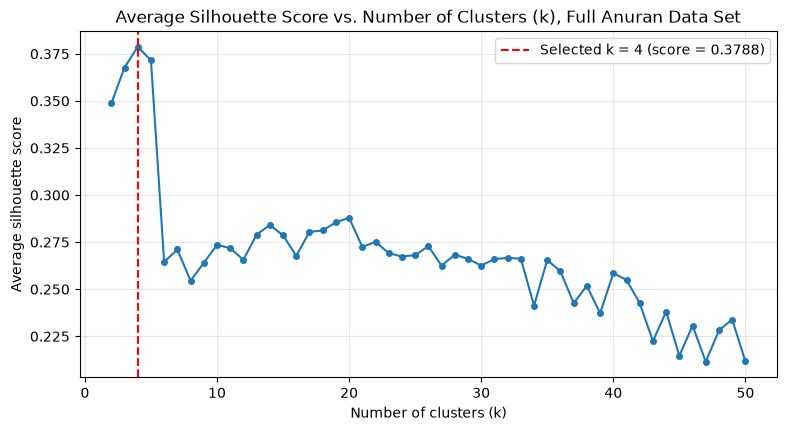

In [18]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances, silhouette_score

# Use the full data set (no train/test split, since this is unsupervised)
df = pd.read_csv("data/Frogs_MFCCs.csv")
X_full = df.iloc[:, 0:22].to_numpy()
y_full = df[["Family", "Genus", "Species"]]

# Pairwise distances are the same for every k and every run, so compute them once
D_full = pairwise_distances(X_full)


def find_optimal_k_silhouette(X, D, k_min=2, k_max=50, random_state=42):
    """Choose k by the highest average silhouette score.

    k = 1 is excluded because the silhouette score is undefined for one cluster.
    """
    k_values = list(range(k_min, k_max + 1))
    sil_scores = []

    for k in k_values:
        kmeans = KMeans(n_clusters=k, n_init=10, random_state=random_state)
        cluster_labels = kmeans.fit_predict(X)
        sil_scores.append(silhouette_score(D, cluster_labels, metric="precomputed"))

    best_idx = int(np.argmax(sil_scores))
    return k_values[best_idx], sil_scores[best_idx], k_values, sil_scores


# Single run to illustrate the selection of k
start = time.time()
best_k, best_score, k_vals, scores = find_optimal_k_silhouette(X_full, D_full, random_state=42)
elapsed = time.time() - start

print(f"Selected k = {best_k} (average silhouette score = {best_score:.4f})")
print(f"Time for one run: {elapsed:.1f} s, so about {50 * elapsed / 60:.0f} min for 50 runs")

plt.figure(figsize=(9, 4.5))
plt.plot(k_vals, scores, marker="o", markersize=4, linewidth=1.5)
plt.axvline(best_k, color="red", linestyle="--",
            label=f"Selected k = {best_k} (score = {best_score:.4f})")
plt.title("Average Silhouette Score vs. Number of Clusters (k), Full Anuran Data Set")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Average silhouette score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Result (single run):** the silhouette method selects $k = 4$, with an average silhouette score of 0.3788.

- The score rises from $k = 2$ to a peak at $k = 4$, stays close at $k = 5$, then drops sharply at $k = 6$ and declines gradually for larger $k$. The peak is clear, so $k = 4$ is a well-supported choice.
- The selected $k = 4$ matches the number of families in the data set (4), and is smaller than the number of genera (8) and species (10). This suggests the clusters capture structure at roughly the family level, so cluster-based labels are expected to be less accurate for genus and species.
- A score of about 0.38 indicates moderate cluster structure: the clusters are distinguishable but overlap.

### 2(b) Majority Label Triplet per Cluster

For each cluster, the true labels of its members are read and the majority family, majority genus, and majority species are determined, each independently. Every observation in the cluster is then assigned that majority triplet (family, genus, species).

### 2(c) Hamming Distance, Hamming Score, and Hamming Loss

The cluster-assigned labels are compared with the true labels over all $n = 7195$ observations and $L = 3$ labels:

- **Average Hamming distance:** the number of labels (0 to 3) on which the assigned triplet differs from the true triplet, averaged over all observations.
- **Hamming loss:** the fraction of all label assignments that are wrong, which equals the average Hamming distance divided by 3.
- **Hamming score:** the fraction of all label assignments that are correct, $1 - \text{Hamming loss}$.

The cell below defines a function that performs 2(a), 2(b), and 2(c) for one random initialization, and shows the detailed output for a single run. The same function is reused in the Monte Carlo simulation.

In [19]:
labels = ["Family", "Genus", "Species"]


def run_single_kmeans_simulation(X, D, y, random_state=42, verbose=False):
    """Run 2(a), 2(b), 2(c) once: choose k, assign majority labels, compute Hamming metrics."""
    # 2(a): choose k in {2, ..., 50} by the highest average silhouette score
    best_k, best_sil, best_labels = None, -1.0, None
    for k in range(2, 51):
        km = KMeans(n_clusters=k, n_init=10, random_state=random_state)
        cluster_ids = km.fit_predict(X)
        sil = silhouette_score(D, cluster_ids, metric="precomputed")
        if sil > best_sil:
            best_k, best_sil, best_labels = k, sil, cluster_ids

    # 2(b): majority family, genus, and species in each cluster
    y_assigned = pd.DataFrame(index=y.index, columns=labels, dtype=object)
    cluster_summary = []

    for c in range(best_k):
        mask = best_labels == c
        cluster_true = y.loc[mask]
        row = {"Cluster": c, "Size": int(mask.sum())}

        for label in labels:
            majority = cluster_true[label].mode()[0]
            y_assigned.loc[mask, label] = majority
            row[f"Majority {label}"] = majority

        cluster_summary.append(row)

    # 2(c): Hamming distance, loss, and score between true and cluster-assigned labels
    mismatches = y[labels].to_numpy() != y_assigned[labels].to_numpy()  # shape (n, 3)

    avg_hamming_dist = mismatches.sum(axis=1).mean()  # wrong labels per instance, 0 to 3
    hamming_loss = mismatches.mean()                  # fraction of wrong labels, 0 to 1
    hamming_score = 1.0 - hamming_loss

    if verbose:
        print(f"Selected k = {best_k} (average silhouette score = {best_sil:.4f})")
        display(pd.DataFrame(cluster_summary))
        for i, label in enumerate(labels):
            print(f"Mismatch rate for {label}: {mismatches[:, i].mean():.4f}")
        print(f"Average Hamming Distance: {avg_hamming_dist:.4f}")
        print(f"Hamming Loss:             {hamming_loss:.4f}")
        print(f"Hamming Score:            {hamming_score:.4f}")

    return best_k, avg_hamming_dist, hamming_loss, hamming_score


# Single run with detailed output for 2(b) and 2(c)
_ = run_single_kmeans_simulation(X_full, D_full, y_full, random_state=42, verbose=True)

Selected k = 4 (average silhouette score = 0.3788)


,Cluster,Size,Majority Family,Majority Genus,Majority Species
0,0,3568,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,614,Hylidae,Hypsiboas,HypsiboasCinerascens
2,2,1031,Dendrobatidae,Ameerega,Ameeregatrivittata
3,3,1982,Hylidae,Hypsiboas,HypsiboasCordobae


Mismatch rate for Family: 0.1936
Mismatch rate for Genus: 0.2292
Mismatch rate for Species: 0.2445
Average Hamming Distance: 0.6673
Hamming Loss:             0.2224
Hamming Score:            0.7776


**Results (single run, k = 4)**

| Cluster | Size | Majority Family | Majority Genus | Majority Species |
|---|---|---|---|---|
| 0 | 3568 | Leptodactylidae | Adenomera | AdenomeraHylaedactylus |
| 1 | 614 | Hylidae | Hypsiboas | HypsiboasCinerascens |
| 2 | 1031 | Dendrobatidae | Ameerega | Ameeregatrivittata |
| 3 | 1982 | Hylidae | Hypsiboas | HypsiboasCordobae |

| Metric | Value |
|---|---|
| Mismatch rate, Family | 0.1936 |
| Mismatch rate, Genus | 0.2292 |
| Mismatch rate, Species | 0.2445 |
| Average Hamming Distance | 0.6673 |
| Hamming Loss | 0.2224 |
| Hamming Score | 0.7776 |

**Observations**

- On average, the cluster-assigned triplet differs from the true triplet on 0.67 of the 3 labels, so about 78% of all label assignments are correct.
- The mismatch rate grows from Family (19.4%) to Genus (22.9%) to Species (24.5%). With only 4 clusters, at most 4 distinct triplets can be assigned, so only 3 of the 4 families, 3 of the 8 genera, and 4 of the 10 species are ever predicted. Every observation from the remaining classes is necessarily mislabeled.
- Although $k = 4$ equals the number of families, the clusters do not correspond one-to-one to the families. Two clusters (1 and 3) share the majority family Hylidae and the majority genus Hypsiboas, and differ only in species. The smallest family, Bufonidae, is not the majority in any cluster.
- K-means is unsupervised and uses only distances between MFCC features, so it performs far worse than the supervised SVMs in Problem 1 (Hamming loss 0.2224 versus 0.0076 for the Gaussian SVM). The two are not strictly comparable, since the SVMs were evaluated on a held-out test set and the clustering on the full data set.

### Monte-Carlo Simulation

K-means starts from random initial centroids, so its result can change from run to run. To account for this, the full procedure of 2(a), 2(b), and 2(c) is repeated 50 times, each with a different random seed (0 to 49):

1. Choose $k \in \{2, \dots, 50\}$ by the highest average silhouette score.
2. Find the majority (family, genus, species) triplet in each cluster and assign it to the cluster's members.
3. Compute the average Hamming distance, Hamming loss, and Hamming score against the true labels.

The average and standard deviation of the 50 values are reported. The data set is the same in every run, so the only source of randomness is the k-means initialization.

In [20]:
# Monte Carlo: repeat 2(a) to 2(c) 50 times with different random initializations
n_runs = 50
mc_results = []

start = time.time()
for run in range(n_runs):
    k, h_dist, h_loss, h_score = run_single_kmeans_simulation(
        X_full, D_full, y_full, random_state=run
    )
    mc_results.append({
        "Run": run + 1,
        "k": k,
        "Hamming Distance": h_dist,
        "Hamming Loss": h_loss,
        "Hamming Score": h_score,
    })
    if (run + 1) % 10 == 0:
        print(f"Completed {run + 1}/{n_runs} runs ({(time.time() - start) / 60:.1f} min)")

mc_df = pd.DataFrame(mc_results)

print("\nValues of k selected across the 50 runs:")
print(mc_df["k"].value_counts().sort_index().to_string())

summary = mc_df[["Hamming Distance", "Hamming Loss", "Hamming Score"]].agg(["mean", "std"]).T
summary.columns = ["Average", "Standard Deviation"]
print("\nMonte Carlo summary over 50 runs:")
display(summary.round(4))

Completed 10/50 runs (3.0 min)
Completed 20/50 runs (6.0 min)
Completed 30/50 runs (9.0 min)
Completed 40/50 runs (12.1 min)
Completed 50/50 runs (15.3 min)

Values of k selected across the 50 runs:
k
4    50

Monte Carlo summary over 50 runs:


,Average,Standard Deviation
Hamming Distance,0.6719,0.0170
Hamming Loss,0.2240,0.0057
Hamming Score,0.7760,0.0057


#### Monte-Carlo Results (50 runs)

**Selected k:** the silhouette method chose $k = 4$ in all 50 runs.

| Metric | Average | Standard Deviation |
|---|---|---|
| Hamming Distance | 0.6719 | 0.0170 |
| Hamming Loss | 0.2240 | 0.0057 |
| Hamming Score | 0.7760 | 0.0057 |

**Observations**

- The choice of $k$ is completely stable: every run selected $k = 4$, so the silhouette peak at $k = 4$ seen in 2(a) is not an artifact of one initialization.
- On average, the cluster-assigned triplet is wrong on about 0.67 of the 3 labels, so about 77.6% of all label assignments are correct.
- The standard deviation is small but not zero. Even with the same $k$, different initializations lead k-means to slightly different local optima, which shift some observations between clusters. The variation is minor relative to the mean (about 2.5% of the Hamming distance), so the results are robust to initialization.
- As expected, Hamming loss equals the Hamming distance divided by 3, and Hamming score equals 1 minus Hamming loss, so the three metrics carry the same information on different scales.
- The single run in 2(b) and 2(c) (Hamming distance 0.6673) lies within one standard deviation of the Monte Carlo average, so it was a representative run.
- The main source of error is structural, not random: with only 4 clusters, at most 4 distinct label triplets can be assigned, while the data contains 4 families, 8 genera, and 10 species. Observations from classes that never form a cluster majority are always mislabeled, which places a floor on the Hamming loss regardless of initialization.

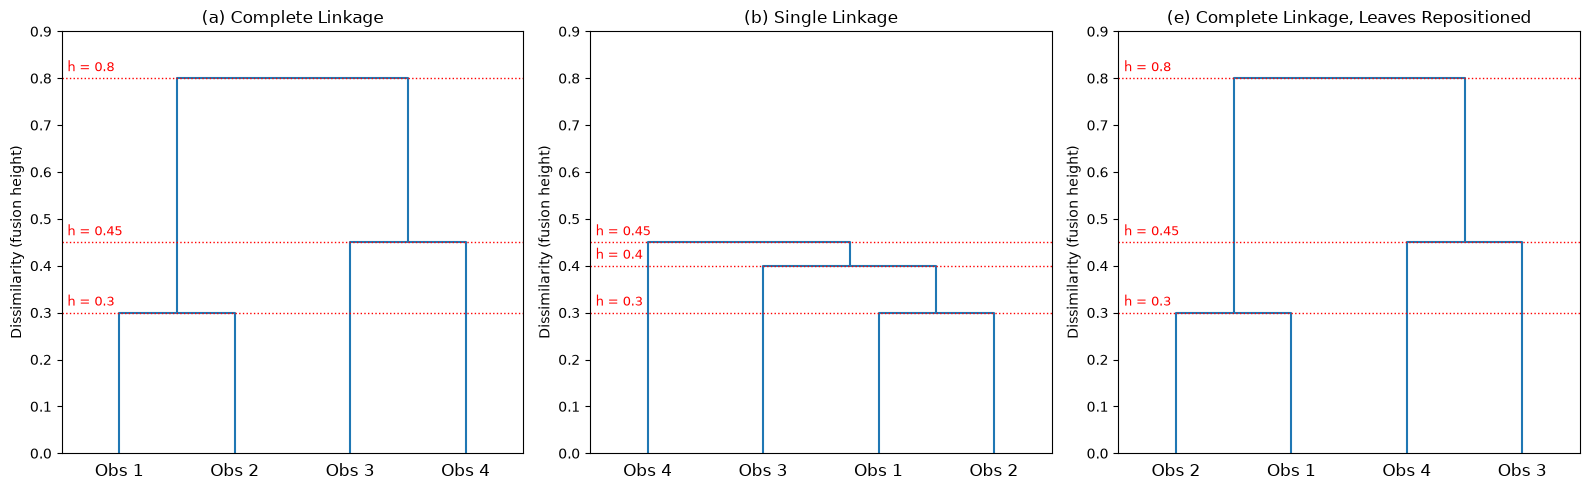

(c) Complete linkage, two clusters: {Obs 1, Obs 2} and {Obs 3, Obs 4}
(d) Single linkage, two clusters: {Obs 1, Obs 2, Obs 3} and {Obs 4}


In [21]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform

# Dissimilarity matrix from ISLR 12.6.2
D = np.array([
    [0.0, 0.3, 0.4, 0.7],
    [0.3, 0.0, 0.5, 0.8],
    [0.4, 0.5, 0.0, 0.45],
    [0.7, 0.8, 0.45, 0.0],
])
obs_labels = ["Obs 1", "Obs 2", "Obs 3", "Obs 4"]

# scipy needs the condensed (upper-triangle) form of the matrix
Z_complete = linkage(squareform(D), method="complete")
Z_single = linkage(squareform(D), method="single")

# (e) Same complete-linkage clustering with the observations listed in reverse order,
# which repositions the leaves without changing any fusion or height
perm = [3, 2, 1, 0]
Z_complete_perm = linkage(squareform(D[np.ix_(perm, perm)]), method="complete")
perm_labels = [obs_labels[i] for i in perm]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
plots = [
    (Z_complete, obs_labels, "(a) Complete Linkage", [0.3, 0.45, 0.8]),
    (Z_single, obs_labels, "(b) Single Linkage", [0.3, 0.4, 0.45]),
    (Z_complete_perm, perm_labels, "(e) Complete Linkage, Leaves Repositioned", [0.3, 0.45, 0.8]),
]

for ax, (Z, tick_labels, title, heights) in zip(axes, plots):
    dendrogram(Z, labels=tick_labels, ax=ax, color_threshold=0)
    ax.set_title(title)
    ax.set_ylabel("Dissimilarity (fusion height)")
    ax.set_ylim(0, 0.9)
    for h in heights:
        ax.axhline(h, color="red", linestyle=":", linewidth=1)
        ax.text(0.5, h + 0.015, f"h = {h}", color="red", fontsize=9)

plt.tight_layout()
plt.show()


def show_clusters(Z, name):
    """Cut the dendrogram into two clusters and print the members of each."""
    ids = fcluster(Z, t=2, criterion="maxclust")
    groups = [[obs_labels[i] for i in range(4) if ids[i] == c] for c in sorted(set(ids))]
    print(f"{name}: " + " and ".join("{" + ", ".join(g) + "}" for g in groups))


show_clusters(Z_complete, "(c) Complete linkage, two clusters")
show_clusters(Z_single, "(d) Single linkage, two clusters")